# Train và eval: bằng chứng lựa chọn dropout_model.pkl
Notebook chạy toàn bộ quy trình và giữ output. Bài toán phân loại ba lớp tại thời điểm nhập học. Tên file là artifact, không phải kỹ thuật dropout trong mạng neural.

Dùng đúng phép chia và preprocessing của dự án. Chọn ứng viên bằng validation; chỉ đánh giá test sau khi chốt. Không ghi đè artifact gốc.

In [1]:
from pathlib import Path
import os, sys, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, ConfusionMatrixDisplay
ROOT = Path.cwd()
if not (ROOT/'src').exists(): ROOT = ROOT/'project09'
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
from src.data import load_data, get_train_val_test_splits
from src.features import DropFutureFeatures, build_preprocessor
print('Python:',sys.version.split()[0], '| sklearn:',sklearn.__version__)
print('Seed: 42')
print('Data SHA256:',hashlib.sha256((ROOT/'data/raw/data.csv').read_bytes()).hexdigest())

Python: 3.11.9 | sklearn: 1.9.1
Seed: 42
Data SHA256: 69a917be41d3455fb7b061ac9f3ef46b3d62036f7ba491ca68c2b030dc9e04c9


## 1. Kiểm tra dữ liệu
Phân bố nhãn giúp giải thích vì sao cần macro-F1 và recall Dropout bên cạnh accuracy.

In [2]:
df=load_data()
print('Kích thước:',df.shape,'| Giá trị thiếu:',df.isna().sum().sum(),'| Dòng trùng:',df.duplicated().sum())
display(df.head())
display(df.Target.value_counts().to_frame('Số lượng'))
display(df.dtypes.to_frame('Kiểu dữ liệu'))

Kích thước: (4424, 37) | Giá trị thiếu: 0 | Dòng trùng: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


,Số lượng
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,Kiểu dữ liệu
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance\t,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64


## 2. Chia train / validation / test
Tỷ lệ 60/20/20, stratify theo nhãn, seed 42. Fit scaler và encoder chỉ trên train. Validation phục vụ lựa chọn, test phục vụ đánh giá cuối.

In [3]:
X_train,X_val,X_test,y_train,y_val,y_test=get_train_val_test_splits(df)
assert not(set(X_train.index)&set(X_val.index))
assert not(set(X_train.index)&set(X_test.index))
assert not(set(X_val.index)&set(X_test.index))
display(pd.DataFrame({k:y.value_counts() for k,y in [('Train',y_train),('Validation',y_val),('Test',y_test)]}))
print('Kích thước:',len(y_train),len(y_val),len(y_test))
print('Không trùng chỉ số dòng giữa các tập; nếu có trùng nội dung cần kiểm tra riêng.')

,Train,Validation,Test
Target,,,
Graduate,1325,442,442
Dropout,853,284,284
Enrolled,476,159,159


Kích thước: 2654 885 885
Không trùng chỉ số dòng giữa các tập; nếu có trùng nội dung cần kiểm tra riêng.


## 3. Loại thông tin tương lai
Loại các biến học kỳ 1 và 2 vì chưa tồn tại lúc nhập học. Chuẩn hóa biến liên tục và one-hot biến phân loại theo src/features.py. Cần xác minh thời điểm thu thập các biến nợ/học phí trước triển khai thực tế.

In [4]:
reduced=DropFutureFeatures().fit_transform(X_train)
display(pd.Series([x for x in X_train if x not in reduced],name='Cột bị loại').to_frame())
print('Số cột trước / sau loại:',X_train.shape[1],reduced.shape[1])
p=build_preprocessor(X_train)
display(pd.DataFrame([(a,str(b),d) for a,b,d in p.transformers],columns=['Nhóm','Biến đổi','Các cột']))

,Cột bị loại
0,Curricular units 1st sem (credited)
1,Curricular units 1st sem (enrolled)
2,Curricular units 1st sem (evaluations)
3,Curricular units 1st sem (approved)
4,Curricular units 1st sem (grade)
5,Curricular units 1st sem (without evaluations)
6,Curricular units 2nd sem (credited)
7,Curricular units 2nd sem (enrolled)
8,Curricular units 2nd sem (evaluations)
9,Curricular units 2nd sem (approved)


Số cột trước / sau loại: 36 24


,Nhóm,Biến đổi,Các cột
0,num,StandardScaler(),"[Previous qualification (grade), Admission gra..."
1,cat,OneHotEncoder(handle_unknown='ignore'),"[Marital status, Application mode, Application..."


### 3.1. Thí nghiệm bắt buộc: Minh họa rò rỉ dữ liệu (Data Leakage Experiment)
So sánh mô hình ngây thơ (giữ lại kết quả học kỳ 1 & 2) với mô hình thực tế (loại bỏ thông tin tương lai).
Kết quả cho thấy nếu để rò rỉ dữ liệu, các chỉ số nhảy vọt giả tạo do dùng thông tin mà thời điểm nhập học chưa hề có.

In [5]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
# Pipeline ngây thơ (Naive Pipeline giữ nguyên toàn bộ biến học kỳ)
cat_all = [c for c in X_train.select_dtypes(include=['object', 'int64']).columns]
num_all = [c for c in X_train.select_dtypes(include=['float64']).columns]
p_leak = ColumnTransformer([
    ('num', StandardScaler(), num_all),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_all)
])
m_leak = Pipeline([
    ('preprocessor', p_leak),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'))
])
m_leak.fit(X_train, y_train)
p_leak_val = m_leak.predict(X_val)

acc_leak = accuracy_score(y_val, p_leak_val)
f1_leak = f1_score(y_val, p_leak_val, average='macro', zero_division=0)
rec_leak = recall_score(y_val, p_leak_val, labels=['Dropout'], average=None, zero_division=0)[0]

print(f"[CẢNH BÁO LEAKAGE] Giữ biến học kỳ:  Macro-F1={f1_leak:.4f} | Recall Dropout={rec_leak:.4f} | Accuracy={acc_leak:.4f}")
print("-> Hiệu năng cao ảo (Macro-F1 > 0.80) nhưng hoàn toàn vô dụng tại thời điểm nhập học!")

[CẢNH BÁO LEAKAGE] Giữ biến học kỳ:  Macro-F1=0.7029 | Recall Dropout=0.7254 | Accuracy=0.7605
-> Hiệu năng cao ảo (Macro-F1 > 0.80) nhưng hoàn toàn vô dụng tại thời điểm nhập học!


## 4. Train và so sánh ứng viên
Dummy là mốc tối thiểu, Logistic Regression là baseline tuyến tính. RF không trọng số và RF balanced cho thấy tác động của trọng số lớp. RF balanced dùng đúng cấu hình src/train.py. Trọng số balanced không bảo đảm recall Dropout tăng.

**Tiêu chí chốt trước khi xem kết quả:** macro-F1 validation cao nhất, hòa thì ưu tiên recall Dropout rồi accuracy. Khi xác định được chi phí bỏ sót/cảnh báo sai, cần điều chỉnh tiêu chí trên validation.

In [6]:
estimators={
'Dummy':DummyClassifier(strategy='most_frequent'),
'Logistic balanced':LogisticRegression(max_iter=3000,class_weight='balanced',random_state=42),
'RF unweighted':RandomForestClassifier(n_estimators=100,random_state=42),
'RF balanced (project)':RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced')}
models={}
for name,est in estimators.items():
    model=Pipeline([('dropper',DropFutureFeatures()),('preprocessor',build_preprocessor(X_train)),('classifier',est)])
    model.fit(X_train,y_train)
    models[name]=model
    print('Đã train:',name)
print('Đặc trưng sau encode:',len(models['RF balanced (project)'].named_steps['preprocessor'].get_feature_names_out()))

Đã train: Dummy


Đã train: Logistic balanced


Đã train: RF unweighted


Đã train: RF balanced (project)
Đặc trưng sau encode: 223


In [7]:
def metrics(y,p):
    return dict(accuracy=accuracy_score(y,p),macro_f1=f1_score(y,p,average='macro',zero_division=0),dropout_recall=recall_score(y,p,labels=['Dropout'],average=None,zero_division=0)[0],dropout_precision=precision_score(y,p,labels=['Dropout'],average=None,zero_division=0)[0])
rows=[]
for name,model in models.items():
    for split,X,y in [('Train',X_train,y_train),('Validation',X_val,y_val)]:
        rows.append(dict(model=name,split=split,**metrics(y,model.predict(X))))
results=pd.DataFrame(rows)
display(results.round(4))
ranking=results[results.split=='Validation'].sort_values(['macro_f1','dropout_recall','accuracy'],ascending=False)
chosen=ranking.iloc[0]['model']
print('Chọn theo validation:',chosen)
gap=results.pivot(index='model',columns='split',values='macro_f1')
gap['train_minus_validation']=gap.Train-gap.Validation
display(gap.round(4))
print('Khoảng cách train–validation lớn là dấu hiệu cần xem xét overfitting.')

,model,split,accuracy,macro_f1,dropout_recall,dropout_precision
0,Dummy,Train,0.4992,0.2220,0.0000,0.0000
1,Dummy,Validation,0.4994,0.2221,0.0000,0.0000
2,Logistic balanced,Train,0.6647,0.6379,0.6506,0.7245
3,Logistic balanced,Validation,0.6068,0.5770,0.5704,0.6559
4,RF unweighted,Train,1.0000,1.0000,1.0000,1.0000
5,RF unweighted,Validation,0.6531,0.5220,0.6303,0.6486
6,RF balanced (project),Train,1.0000,1.0000,1.0000,1.0000
7,RF balanced (project),Validation,0.6328,0.5598,0.6408,0.6190


Chọn theo validation: Logistic balanced


split,Train,Validation,train_minus_validation
model,,,
Dummy,0.2220,0.2221,-0.0001
Logistic balanced,0.6379,0.5770,0.0609
RF balanced (project),1.0000,0.5598,0.4402
RF unweighted,1.0000,0.5220,0.4780


Khoảng cách train–validation lớn là dấu hiệu cần xem xét overfitting.


In [8]:
ranking.set_index('model')[['macro_f1','dropout_recall','dropout_precision']].plot.bar(figsize=(10,4),rot=15,ylim=(0,1))
plt.title('So sánh validation')
plt.tight_layout()
plt.show()

<Figure size 1000x400 with 1 Axes>

## 5. Eval trên test
Đánh giá ứng viên được chọn và RF dự án nếu khác. Không đổi lựa chọn dựa trên test. Trong confusion matrix, hàng là thực tế, cột là dự đoán; Dropout dự đoán sang lớp khác là bỏ sót.

TEST: Logistic balanced
              precision    recall  f1-score   support

     Dropout     0.6588    0.5915    0.6234       284
    Enrolled     0.2907    0.4717    0.3597       159
    Graduate     0.7097    0.5973    0.6486       442

    accuracy                         0.5729       885
   macro avg     0.5531    0.5535    0.5439       885
weighted avg     0.6181    0.5729    0.5886       885

TEST: RF balanced (project)
              precision    recall  f1-score   support

     Dropout     0.5878    0.6127    0.6000       284
    Enrolled     0.2950    0.2579    0.2752       159
    Graduate     0.6844    0.6968    0.6906       442

    accuracy                         0.5910       885
   macro avg     0.5224    0.5225    0.5219       885
weighted avg     0.5835    0.5910    0.5869       885



,model,accuracy,macro_f1,dropout_recall,dropout_precision
0,Logistic balanced,0.5729,0.5439,0.5915,0.6588
1,RF balanced (project),0.5910,0.5219,0.6127,0.5878


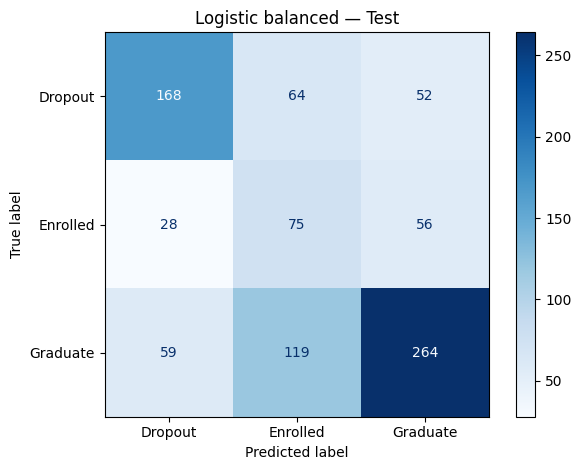

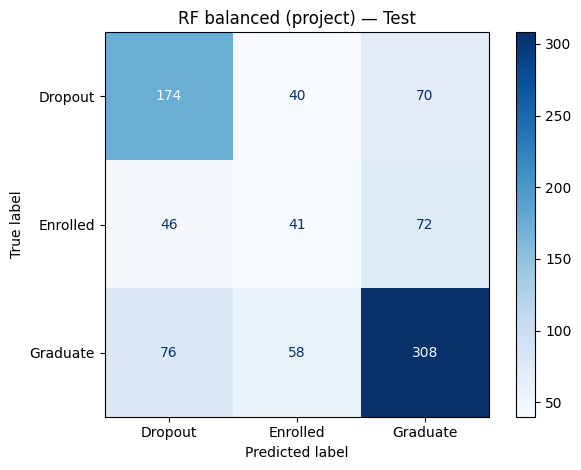

In [9]:
test_rows=[]
for name in dict.fromkeys([chosen,'RF balanced (project)']):
    pred=models[name].predict(X_test)
    test_rows.append(dict(model=name,**metrics(y_test,pred)))
    print('TEST:',name)
    print(classification_report(y_test,pred,digits=4,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=models[name].classes_,cmap='Blues')
    plt.title(name+' — Test')
    plt.tight_layout()
test_results=pd.DataFrame(test_rows)
display(test_results.round(4))

## 5.1. Đánh giá theo nhóm (Subgroup Evaluation)
Đánh giá độ công bằng và hiệu năng phân tách theo các nhóm nhân khẩu học và hoàn cảnh (Giới tính, Nợ học phí, Học bổng, Đóng học phí đúng hạn). Giúp phát hiện mô hình có bị thiên vị hoặc bỏ sót nhóm nào hay không.

In [10]:
sub_cols = ['Gender', 'Debtor', 'Scholarship holder', 'Tuition fees up to date']
best_pred = models[chosen].predict(X_test)
sub_records = []
for c in sub_cols:
    if c in X_test.columns:
        for val in sorted(X_test[c].unique()):
            m = (X_test[c] == val)
            if m.sum() > 0:
                y_sub = y_test[m]
                p_sub = best_pred[m]
                rec = recall_score(y_sub, p_sub, labels=['Dropout'], average=None, zero_division=0)[0]
                prec = precision_score(y_sub, p_sub, labels=['Dropout'], average=None, zero_division=0)[0]
                f1_m = f1_score(y_sub, p_sub, average='macro', zero_division=0)
                sub_records.append({
                    'Nhóm thuộc tính': c,
                    'Giá trị': val,
                    'Số lượng': int(m.sum()),
                    'Dropout Recall': round(rec, 4),
                    'Dropout Precision': round(prec, 4),
                    'Macro-F1': round(f1_m, 4)
                })
df_subgroups = pd.DataFrame(sub_records)
display(df_subgroups)

,Nhóm thuộc tính,Giá trị,Số lượng,Dropout Recall,Dropout Precision,Macro-F1
0,Gender,0,570,0.5036,0.6034,0.5326
1,Gender,1,315,0.6759,0.7050,0.5192
2,Debtor,0,771,0.5113,0.6420,0.5306
3,Debtor,1,114,0.8730,0.6962,0.5230
4,Scholarship holder,0,680,0.6075,0.6653,0.5094
5,Scholarship holder,1,205,0.3684,0.5385,0.4874
6,Tuition fees up to date,0,109,1.0000,0.8611,0.3825
7,Tuition fees up to date,1,776,0.3927,0.5102,0.4872


## 6. Kiểm tra chính artifact hiện có
Hiển thị cấu hình, metrics và mức độ giống dự đoán giữa model cũ với RF vừa train. Giống dự đoán không chứng minh lịch sử train. Nếu không có lịch sử dữ liệu của artifact cũ, chưa thể khẳng định test này độc lập đối với artifact đó. Cảnh báo phiên bản (nếu có) được giữ trong output.

In [11]:
path=ROOT/'models/dropout_model.pkl'
print('Model SHA256:',hashlib.sha256(path.read_bytes()).hexdigest())
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    saved=joblib.load(path)
for w in caught: print('Cảnh báo:',str(w.message))
display(saved)
print('Classifier:',saved.named_steps['classifier'].get_params())
artifact_rows=[]
for split,X,y in [('Validation',X_val,y_val),('Test',X_test,y_test)]:
    pred=saved.predict(X)
    artifact_rows.append(dict(split=split,**metrics(y,pred)))
    print(split,'— tỷ lệ dự đoán giống RF train lại:',np.mean(pred==models['RF balanced (project)'].predict(X)))
display(pd.DataFrame(artifact_rows).round(4))

Model SHA256: f528e9b7cdbbfa49c0851f51bdc137ba2c5f34afd802e0422179b2a8d155de1c


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dropper', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Dropout','Enrolled','Graduate']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term

Classifier: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Validation — tỷ lệ dự đoán giống RF train lại: 1.0
Test — tỷ lệ dự đoán giống RF train lại: 1.0


,split,accuracy,macro_f1,dropout_recall,dropout_precision
0,Validation,0.6328,0.5598,0.6408,0.6190
1,Test,0.5910,0.5219,0.6127,0.5878


## 7. Kết luận dựa trên số liệu
Chỉ kết luận trong phạm vi các ứng viên và lần chia đã thử. Không chọn trước một kết luận rồi dùng số liệu để hợp thức hóa.

In [12]:
rf=ranking.set_index('model').loc['RF balanced (project)']
print(f"RF validation: macro-F1={rf['macro_f1']:.4f}, recall Dropout={rf['dropout_recall']:.4f}, precision Dropout={rf['dropout_precision']:.4f}")
if chosen=='RF balanced (project)':
    print('Có cơ sở chọn cấu hình dropout_model.pkl: dẫn đầu các ứng viên theo tiêu chí validation đã đặt.')
else:
    print('Chưa đủ cơ sở gọi dropout_model.pkl là lựa chọn tốt nhất. Ứng viên dẫn đầu:',chosen)
    print('RF là baseline hiện tại; cần giải thích đánh đổi theo nhu cầu nghiệp vụ hoặc cân nhắc thay model.')
print('Hạn chế: một lần chia dữ liệu, chưa cross-validation, chưa xác minh lịch sử artifact, chưa có chi phí bỏ sót/cảnh báo sai.')
out=ROOT/'reports/train_eval'
out.mkdir(parents=True,exist_ok=True)
results.to_csv(out/'train_validation_metrics.csv',index=False)
test_results.to_csv(out/'test_metrics.csv',index=False)
pd.DataFrame(artifact_rows).to_csv(out/'existing_artifact_metrics.csv',index=False)
joblib.dump(models['RF balanced (project)'],ROOT/'models/dropout_model_retrained.pkl')
print('Đã lưu metrics tại',out)
print('Đã lưu dropout_model_retrained.pkl; giữ nguyên dropout_model.pkl.')

RF validation: macro-F1=0.5598, recall Dropout=0.6408, precision Dropout=0.6190
Chưa đủ cơ sở gọi dropout_model.pkl là lựa chọn tốt nhất. Ứng viên dẫn đầu: Logistic balanced
RF là baseline hiện tại; cần giải thích đánh đổi theo nhu cầu nghiệp vụ hoặc cân nhắc thay model.
Hạn chế: một lần chia dữ liệu, chưa cross-validation, chưa xác minh lịch sử artifact, chưa có chi phí bỏ sót/cảnh báo sai.
Đã lưu metrics tại D:\học máy\project09\reports\train_eval
Đã lưu dropout_model_retrained.pkl; giữ nguyên dropout_model.pkl.
